<a href="https://colab.research.google.com/github/Blackk-dotcom/Data-Science-project/blob/main/Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving DSA1101_Practical_Assignments_Datasets (1).xlsx to DSA1101_Practical_Assignments_Datasets (1).xlsx


In [2]:
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_excel(
    'DSA1101_Practical_Assignments_Datasets (1).xlsx',
    sheet_name='A2_Retail_Sales'
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
df.head()

,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES
0,TX0001,2025-03-20,Coast,Food,2,409.65,0.15,Mobile Money,Store,696.40
1,TX0002,2025-06-29,NaN,Food,8,1047.14,0.00,Mobile Money,Store,8377.12
2,TX0003,2025-06-02,Coast,Clothing,1,1374.69,0.00,Card,Store,1374.69
3,TX0004,2025-04-17,Coast,Clothing,3,3861.90,0.00,Cash,Store,11585.70
4,TX0005,2025-01-05,Western,Food,1,701.62,0.15,Mobile Money,Online,596.38


In [7]:
print("Rows and columns:", df.shape)


Rows and columns: (262, 10)


In [8]:
import pandas as pd

df = pd.read_excel(
    'DSA1101_Practical_Assignments_Datasets (1).xlsx',
    sheet_name='A2_Retail_Sales'
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [9]:
df.head()

,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES
0,TX0001,2025-03-20,Coast,Food,2,409.65,0.15,Mobile Money,Store,696.40
1,TX0002,2025-06-29,NaN,Food,8,1047.14,0.00,Mobile Money,Store,8377.12
2,TX0003,2025-06-02,Coast,Clothing,1,1374.69,0.00,Card,Store,1374.69
3,TX0004,2025-04-17,Coast,Clothing,3,3861.90,0.00,Cash,Store,11585.70
4,TX0005,2025-01-05,Western,Food,1,701.62,0.15,Mobile Money,Online,596.38


In [11]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset dimensions:", df.shape)


Number of rows: 262
Number of columns: 10
Dataset dimensions: (262, 10)


In [12]:
print("Column names in the dataset:")

for column in df.columns:
    print(column)

Column names in the dataset:
Transaction_ID
Date
Region
Product_Category
Units_Sold
Unit_Price_KES
Discount_Rate
Payment_Method
Sales_Channel
Revenue_KES


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    262 non-null    object        
 1   Date              262 non-null    datetime64[ns]
 2   Region            257 non-null    object        
 3   Product_Category  262 non-null    object        
 4   Units_Sold        262 non-null    int64         
 5   Unit_Price_KES    257 non-null    float64       
 6   Discount_Rate     262 non-null    float64       
 7   Payment_Method    257 non-null    object        
 8   Sales_Channel     262 non-null    object        
 9   Revenue_KES       262 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(5)
memory usage: 20.6+ KB


In [14]:
df.describe()

,Date,Units_Sold,Unit_Price_KES,Discount_Rate,Revenue_KES
count,262,262.000000,257.000000,262.000000,262.000000
mean,2025-04-03 10:15:34.351144960,4.973282,7143.780156,0.074809,25089.461908
min,2025-01-01 00:00:00,1.000000,81.580000,0.000000,70.540000
25%,2025-02-13 00:00:00,3.000000,1001.510000,0.000000,2934.317500
50%,2025-04-07 12:00:00,5.000000,2483.140000,0.100000,8920.240000
75%,2025-05-25 18:00:00,7.000000,5950.270000,0.100000,22679.162500
max,2025-06-29 00:00:00,100.000000,250000.000000,0.200000,313895.680000
std,NaN,6.341741,17983.687224,0.069170,45980.561641


In [15]:
df.describe(include='all')

,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES
count,262,262,257,262,262.000000,257.000000,262.000000,257,262,262.000000
unique,260,NaN,5,5,NaN,NaN,NaN,4,2,NaN
top,TX0091,NaN,Western,Clothing,NaN,NaN,NaN,Mobile Money,Store,NaN
freq,2,NaN,65,69,NaN,NaN,NaN,120,160,NaN
mean,NaN,2025-04-03 10:15:34.351144960,NaN,NaN,4.973282,7143.780156,0.074809,NaN,NaN,25089.461908
min,NaN,2025-01-01 00:00:00,NaN,NaN,1.000000,81.580000,0.000000,NaN,NaN,70.540000
25%,NaN,2025-02-13 00:00:00,NaN,NaN,3.000000,1001.510000,0.000000,NaN,NaN,2934.317500
50%,NaN,2025-04-07 12:00:00,NaN,NaN,5.000000,2483.140000,0.100000,NaN,NaN,8920.240000
75%,NaN,2025-05-25 18:00:00,NaN,NaN,7.000000,5950.270000,0.100000,NaN,NaN,22679.162500
max,NaN,2025-06-29 00:00:00,NaN,NaN,100.000000,250000.000000,0.200000,NaN,NaN,313895.680000


In [18]:
print("Missing values in each column:")

print(df.isnull().sum())

Missing values in each column:
Transaction_ID      0
Date                0
Region              5
Product_Category    0
Units_Sold          0
Unit_Price_KES      5
Discount_Rate       0
Payment_Method      5
Sales_Channel       0
Revenue_KES         0
dtype: int64


In [19]:
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print(missing_percentage)

Transaction_ID      0.000000
Date                0.000000
Region              1.908397
Product_Category    0.000000
Units_Sold          0.000000
Unit_Price_KES      1.908397
Discount_Rate       0.000000
Payment_Method      1.908397
Sales_Channel       0.000000
Revenue_KES         0.000000
dtype: float64


In [20]:
duplicates = df.duplicated().sum()

print("Total exact duplicate rows:", duplicates)

Total exact duplicate rows: 2


In [21]:
df[df.duplicated(keep=False)]

,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES
20,TX0021,2025-06-09,Western,Electronics,5,32818.79,0.10,Card,Online,147684.56
90,TX0091,2025-05-18,Western,Food,2,433.95,0.05,Bank Transfer,Online,824.50
260,TX0021,2025-06-09,Western,Electronics,5,32818.79,0.10,Card,Online,147684.56
261,TX0091,2025-05-18,Western,Food,2,433.95,0.05,Bank Transfer,Online,824.50


In [22]:
duplicate_ids = df[
    df.duplicated(
        subset=['Transaction_ID'],
        keep=False
    )
]

print("Duplicate transaction identifiers:")
display(duplicate_ids)

Duplicate transaction identifiers:


,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES
20,TX0021,2025-06-09,Western,Electronics,5,32818.79,0.10,Card,Online,147684.56
90,TX0091,2025-05-18,Western,Food,2,433.95,0.05,Bank Transfer,Online,824.50
260,TX0021,2025-06-09,Western,Electronics,5,32818.79,0.10,Card,Online,147684.56
261,TX0091,2025-05-18,Western,Food,2,433.95,0.05,Bank Transfer,Online,824.50


In [23]:
print(
    "Number of duplicate transaction IDs:",
    df['Transaction_ID'].duplicated().sum()
)

Number of duplicate transaction IDs: 2


In [24]:
print("RETAIL DATASET INSPECTION SUMMARY")
print("=" * 40)

print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])

print("Total missing values:",
      df.isnull().sum().sum())

print("Total duplicate rows:",
      df.duplicated().sum())

print("Duplicate transaction IDs:",
      df['Transaction_ID'].duplicated().sum())

print("\nDataset inspection completed.")

RETAIL DATASET INSPECTION SUMMARY
Total records: 262
Total columns: 10
Total missing values: 15
Total duplicate rows: 2
Duplicate transaction IDs: 2

Dataset inspection completed.


In [25]:
# Convert Date column to datetime format

df['Date'] = pd.to_datetime(
    df['Date'],
    errors='coerce'
)

# Display the first five dates
print(df['Date'].head())

# Check the data type
print("\nDate data type:")
print(df['Date'].dtype)

0   2025-03-20
1   2025-06-29
2   2025-06-02
3   2025-04-17
4   2025-01-05
Name: Date, dtype: datetime64[ns]

Date data type:
datetime64[ns]


In [26]:
# Define numeric columns

numeric_columns = [
    'Units_Sold',
    'Unit_Price_KES',
    'Discount_Rate',
    'Revenue_KES'
]

# Convert columns into numeric data types

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors='coerce'
    )

# Display data types

print("Updated data types:")
print(df[numeric_columns].dtypes)

Updated data types:
Units_Sold          int64
Unit_Price_KES    float64
Discount_Rate     float64
Revenue_KES       float64
dtype: object


In [27]:
# Display the first ten records

display(
    df[
        [
            'Units_Sold',
            'Unit_Price_KES',
            'Discount_Rate',
            'Revenue_KES'
        ]
    ].head(10)
)

,Units_Sold,Unit_Price_KES,Discount_Rate,Revenue_KES
0,2,409.65,0.15,696.40
1,8,1047.14,0.00,8377.12
2,1,1374.69,0.00,1374.69
3,3,3861.90,0.00,11585.70
4,1,701.62,0.15,596.38
5,7,8560.44,0.00,59923.08
6,3,1983.68,0.00,5951.04
7,100,11973.82,0.05,68250.77
8,5,30934.86,0.05,146940.58
9,8,921.14,0.10,6632.21


In [28]:
# Check missing values in numeric columns

print("Missing numeric values:")

print(df[numeric_columns].isnull().sum())

Missing numeric values:
Units_Sold        0
Unit_Price_KES    5
Discount_Rate     0
Revenue_KES       0
dtype: int64


In [29]:
# Identify quantities that are zero or negative

invalid_units = df[
    df['Units_Sold'] <= 0
]

print("Invalid quantities sold:")
display(invalid_units)

print(
    "Number of invalid quantity records:",
    len(invalid_units)
)

Invalid quantities sold:


,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES


Number of invalid quantity records: 0


In [30]:
# Identify zero or negative unit prices

invalid_prices = df[
    df['Unit_Price_KES'] <= 0
]

print("Invalid unit prices:")
display(invalid_prices)

print(
    "Number of invalid price records:",
    len(invalid_prices)
)

Invalid unit prices:


,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES


Number of invalid price records: 0


In [31]:
# Discount rate should be between 0 and 1

invalid_discounts = df[
    (df['Discount_Rate'] < 0) |
    (df['Discount_Rate'] > 1)
]

print("Invalid discount rates:")
display(invalid_discounts)

print(
    "Number of invalid discount records:",
    len(invalid_discounts)
)

Invalid discount rates:


,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES


Number of invalid discount records: 0


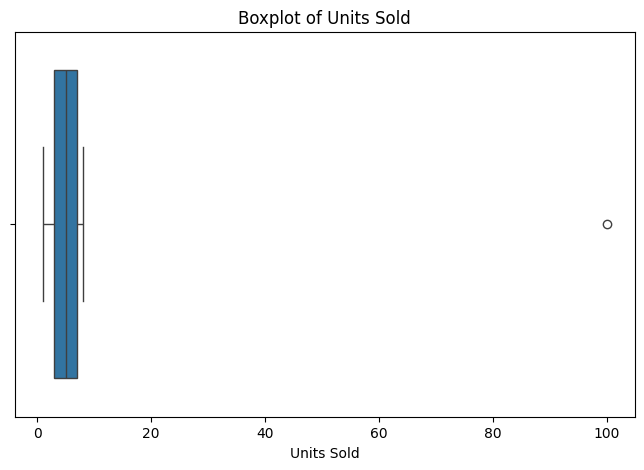

In [32]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df['Units_Sold'])

plt.title('Boxplot of Units Sold')
plt.xlabel('Units Sold')

plt.show()

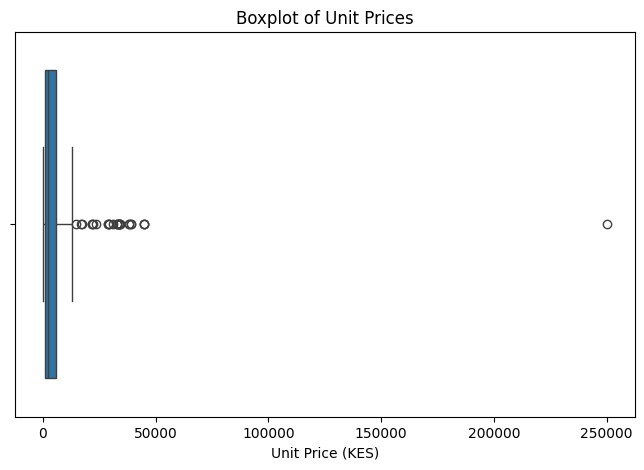

In [33]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df['Unit_Price_KES'])

plt.title('Boxplot of Unit Prices')
plt.xlabel('Unit Price (KES)')

plt.show()

In [34]:
# Display updated dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    262 non-null    object        
 1   Date              262 non-null    datetime64[ns]
 2   Region            257 non-null    object        
 3   Product_Category  262 non-null    object        
 4   Units_Sold        262 non-null    int64         
 5   Unit_Price_KES    257 non-null    float64       
 6   Discount_Rate     262 non-null    float64       
 7   Payment_Method    257 non-null    object        
 8   Sales_Channel     262 non-null    object        
 9   Revenue_KES       262 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(5)
memory usage: 20.6+ KB


In [35]:
print("QUESTION 3: DATA TYPE VERIFICATION")
print("=" * 45)

print("\nDate data type:")
print(df['Date'].dtype)

print("\nNumeric data types:")
print(df[numeric_columns].dtypes)

print("\nMissing values:")
print(df[numeric_columns + ['Date']].isnull().sum())

print("\nInvalid quantities:",
      (df['Units_Sold'] <= 0).sum())

print("Invalid prices:",
      (df['Unit_Price_KES'] <= 0).sum())

print("Invalid discounts:",
      (
          (df['Discount_Rate'] < 0) |
          (df['Discount_Rate'] > 1)
      ).sum())

print("\nQuestion 3 completed successfully!")

QUESTION 3: DATA TYPE VERIFICATION

Date data type:
datetime64[ns]

Numeric data types:
Units_Sold          int64
Unit_Price_KES    float64
Discount_Rate     float64
Revenue_KES       float64
dtype: object

Missing values:
Units_Sold        0
Unit_Price_KES    5
Discount_Rate     0
Revenue_KES       0
Date              0
dtype: int64

Invalid quantities: 0
Invalid prices: 0
Invalid discounts: 0

Question 3 completed successfully!


In [36]:
# Calculate revenue using the given formula

df['Calculated_Revenue_KES'] = (
    df['Units_Sold'] *
    df['Unit_Price_KES'] *
    (1 - df['Discount_Rate'])
)

print("Revenue recalculated successfully!")

Revenue recalculated successfully!


In [37]:
# Display original and calculated revenue

display(
    df[
        [
            'Units_Sold',
            'Unit_Price_KES',
            'Discount_Rate',
            'Revenue_KES',
            'Calculated_Revenue_KES'
        ]
    ].head(10)
)

,Units_Sold,Unit_Price_KES,Discount_Rate,Revenue_KES,Calculated_Revenue_KES
0,2,409.65,0.15,696.40,696.405
1,8,1047.14,0.00,8377.12,8377.120
2,1,1374.69,0.00,1374.69,1374.690
3,3,3861.90,0.00,11585.70,11585.700
4,1,701.62,0.15,596.38,596.377
5,7,8560.44,0.00,59923.08,59923.080
6,3,1983.68,0.00,5951.04,5951.040
7,100,11973.82,0.05,68250.77,1137512.900
8,5,30934.86,0.05,146940.58,146940.585
9,8,921.14,0.10,6632.21,6632.208


In [38]:
# Calculate the difference

df['Revenue_Difference'] = (
    df['Revenue_KES'] -
    df['Calculated_Revenue_KES']
)

print("Revenue differences calculated successfully!")

display(
    df[
        [
            'Revenue_KES',
            'Calculated_Revenue_KES',
            'Revenue_Difference'
        ]
    ].head(10)
)

Revenue differences calculated successfully!


,Revenue_KES,Calculated_Revenue_KES,Revenue_Difference
0,696.40,696.405,-0.005
1,8377.12,8377.120,0.000
2,1374.69,1374.690,0.000
3,11585.70,11585.700,0.000
4,596.38,596.377,0.003
5,59923.08,59923.080,0.000
6,5951.04,5951.040,0.000
7,68250.77,1137512.900,-1069262.130
8,146940.58,146940.585,-0.005
9,6632.21,6632.208,0.002


In [39]:
# Set rounding tolerance

tolerance = 0.01

# Compare the original and calculated revenue

df['Revenue_Status'] = np.where(
    df['Revenue_Difference'].abs() <= tolerance,
    'Matches',
    'Does Not Match'
)

# Display comparison results

display(
    df[
        [
            'Revenue_KES',
            'Calculated_Revenue_KES',
            'Revenue_Difference',
            'Revenue_Status'
        ]
    ]
)

,Revenue_KES,Calculated_Revenue_KES,Revenue_Difference,Revenue_Status
0,696.40,696.405,-0.005,Matches
1,8377.12,8377.120,0.000,Matches
2,1374.69,1374.690,0.000,Matches
3,11585.70,11585.700,0.000,Matches
4,596.38,596.377,0.003,Matches
...,...,...,...,...
257,69598.36,69598.360,0.000,Matches
258,14040.86,14040.864,-0.004,Matches
259,1951.04,1951.038,0.002,Matches
260,147684.56,147684.555,0.005,Matches


In [40]:
# Identify records where revenue does not match

inconsistent_revenue = df[
    df['Revenue_Status'] == 'Does Not Match'
]

print(
    "Number of inconsistent revenue records:",
    len(inconsistent_revenue)
)

display(inconsistent_revenue)

Number of inconsistent revenue records: 7


,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES,Calculated_Revenue_KES,Revenue_Difference,Revenue_Status
7,TX0008,2025-02-24,Coast,Home,100,11973.82,0.05,Card,Store,68250.77,1137512.9,-1069262.13,Does Not Match
18,TX0019,2025-05-26,Coast,Electronics,6,250000.00,0.05,Card,Online,116623.31,1425000.0,-1308376.69,Does Not Match
77,TX0078,2025-05-30,Rift Valley,Food,7,NaN,0.05,Mobile Money,Store,1626.19,NaN,NaN,Does Not Match
82,TX0083,2025-05-25,Nairobi,Clothing,2,NaN,0.00,Mobile Money,Online,4456.96,NaN,NaN,Does Not Match
96,TX0097,2025-04-02,Western,Food,6,NaN,0.20,Mobile Money,Online,5267.52,NaN,NaN,Does Not Match
130,TX0131,2025-01-22,Coast,Home,2,NaN,0.00,Card,Store,2871.58,NaN,NaN,Does Not Match
211,TX0212,2025-06-06,Coast,Food,6,NaN,0.00,NaN,Store,4158.60,NaN,NaN,Does Not Match


In [41]:
# Count revenue matches and mismatches

revenue_counts = df['Revenue_Status'].value_counts()

print("Revenue comparison summary:")
print(revenue_counts)

# Calculate percentages

revenue_percentages = (
    df['Revenue_Status']
    .value_counts(normalize=True) * 100
)

print("\nRevenue comparison percentages:")
print(revenue_percentages)

Revenue comparison summary:
Revenue_Status
Matches           255
Does Not Match      7
Name: count, dtype: int64

Revenue comparison percentages:
Revenue_Status
Matches           97.328244
Does Not Match     2.671756
Name: proportion, dtype: float64


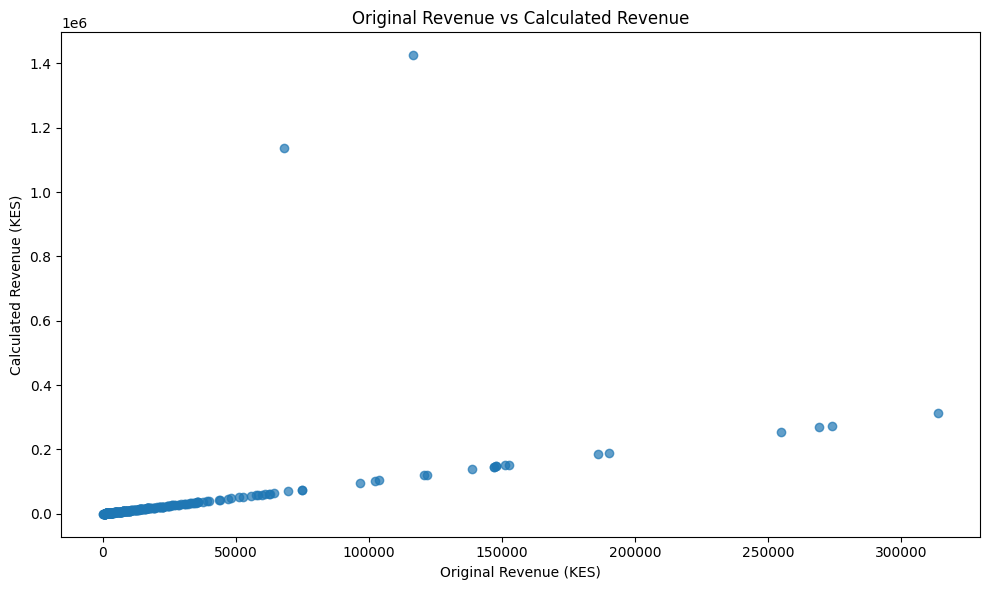

In [42]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['Revenue_KES'],
    df['Calculated_Revenue_KES'],
    alpha=0.7
)

plt.xlabel('Original Revenue (KES)')
plt.ylabel('Calculated Revenue (KES)')

plt.title('Original Revenue vs Calculated Revenue')

plt.tight_layout()
plt.show()

In [43]:
print("QUESTION 4: REVENUE COMPARISON")
print("=" * 45)

print(
    "Total Original Revenue: KES",
    round(df['Revenue_KES'].sum(), 2)
)

print(
    "Total Calculated Revenue: KES",
    round(df['Calculated_Revenue_KES'].sum(), 2)
)

print(
    "Total Revenue Difference: KES",
    round(df['Revenue_Difference'].sum(), 2)
)

print(
    "Matching Records:",
    (df['Revenue_Status'] == 'Matches').sum()
)

print(
    "Inconsistent Records:",
    (df['Revenue_Status'] == 'Does Not Match').sum()
)

print("\nQuestion 4 completed successfully!")

QUESTION 4: REVENUE COMPARISON
Total Original Revenue: KES 6573439.02
Total Calculated Revenue: KES 8932696.98
Total Revenue Difference: KES -2377638.81
Matching Records: 255
Inconsistent Records: 7

Question 4 completed successfully!


In [45]:
# Create a separate copy for cleaning
retail_clean = retail.copy()

# Keep the original data unchanged
print("Original records:", len(retail))
print("Records in cleaning copy:", len(retail_clean))

NameError: name 'retail' is not defined

In [46]:
%whos

Variable                Type         Data/Info
----------------------------------------------
ColumnTransformer       ABCMeta      <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
DecisionTreeRegressor   ABCMeta      <class 'sklearn.tree._cla<...>s.DecisionTreeRegressor'>
DummyRegressor          type         <class 'sklearn.dummy.DummyRegressor'>
LinearRegression        ABCMeta      <class 'sklearn.linear_mo<...>._base.LinearRegression'>
OneHotEncoder           type         <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
Pipeline                ABCMeta      <class 'sklearn.pipeline.Pipeline'>
RandomForestRegressor   ABCMeta      <class 'sklearn.ensemble.<...>t.RandomForestRegressor'>
SimpleImputer           type         <class 'sklearn.impute._base.SimpleImputer'>
column                  str          Revenue_KES
cross_val_score         function     <function cross_val_score at 0x7bb170f0ed40>
df                      DataFrame        Transaction_ID       <...>\n[262 rows 

In [47]:
retail = df.copy()

print("Original records:", len(retail))

Original records: 262


In [49]:
retail_clean = retail.copy()

print("Original records:", len(retail))
print("Cleaning copy records:", len(retail_clean))

Original records: 262
Cleaning copy records: 262


In [50]:
exact_duplicates = retail_clean.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)

Exact duplicate rows: 2


In [51]:
retail_clean = retail_clean.drop_duplicates()

print("Records after removing exact duplicates:", len(retail_clean))

Records after removing exact duplicates: 260


In [52]:
duplicate_ids = retail_clean[
    retail_clean["Transaction_ID"].duplicated(keep=False)
].sort_values("Transaction_ID")

print("Duplicate transaction ID records:")
display(duplicate_ids)

print("Number of duplicate transaction ID records:", len(duplicate_ids))

Duplicate transaction ID records:


,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES,Calculated_Revenue_KES,Revenue_Difference,Revenue_Status


Number of duplicate transaction ID records: 0


In [53]:
missing_values = retail_clean.isnull().sum()

print("Missing values in each column:")
display(missing_values)

Missing values in each column:


,0
Transaction_ID,0
Date,0
Region,5
Product_Category,0
Units_Sold,0
Unit_Price_KES,5
Discount_Rate,0
Payment_Method,5
Sales_Channel,0
Revenue_KES,0


In [54]:
# Prepare data for KPI calculations
sales_data = retail_clean.copy()

# Keep records with valid revenue, units sold and discount
sales_data = sales_data.dropna(
    subset=["Revenue_KES", "Units_Sold", "Discount_Rate"]
)

sales_data = sales_data[
    (sales_data["Units_Sold"] > 0) &
    (sales_data["Revenue_KES"] >= 0) &
    (sales_data["Discount_Rate"].between(0, 1))
]

# Calculate sales KPIs
total_revenue = sales_data["Revenue_KES"].sum()
total_units = sales_data["Units_Sold"].sum()
average_revenue = sales_data["Revenue_KES"].mean()
median_revenue = sales_data["Revenue_KES"].median()
transaction_count = sales_data["Transaction_ID"].nunique()
average_discount = sales_data["Discount_Rate"].mean()

# Display results
print("RETAIL SALES PERFORMANCE KPIs")
print("--------------------------------")
print(f"Total Revenue: KES {total_revenue:,.2f}")
print(f"Total Units Sold: {total_units:,.0f}")
print(f"Average Transaction Revenue: KES {average_revenue:,.2f}")
print(f"Median Transaction Revenue: KES {median_revenue:,.2f}")
print(f"Transaction Count: {transaction_count}")
print(f"Average Discount: {average_discount:.2%}")

RETAIL SALES PERFORMANCE KPIs
--------------------------------
Total Revenue: KES 6,424,929.96
Total Units Sold: 1,296
Average Transaction Revenue: KES 24,711.27
Median Transaction Revenue: KES 8,920.24
Transaction Count: 260
Average Discount: 7.48%


In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare analysis data
sales_data = retail_clean.copy()

# Convert required columns to numeric
numeric_columns = [
    "Revenue_KES",
    "Units_Sold",
    "Unit_Price_KES",
    "Discount_Rate"
]

for col in numeric_columns:
    sales_data[col] = pd.to_numeric(
        sales_data[col], errors="coerce"
    )

# Exclude records with invalid KPI values
sales_data = sales_data.dropna(
    subset=["Revenue_KES", "Units_Sold", "Discount_Rate"]
)

sales_data = sales_data[
    (sales_data["Units_Sold"] > 0) &
    (sales_data["Revenue_KES"] >= 0) &
    (sales_data["Discount_Rate"].between(0, 1))
]

# Calculate KPIs
total_revenue = sales_data["Revenue_KES"].sum()
total_units = sales_data["Units_Sold"].sum()
average_revenue = sales_data["Revenue_KES"].mean()
median_revenue = sales_data["Revenue_KES"].median()
transaction_count = sales_data["Transaction_ID"].nunique()
average_discount = sales_data["Discount_Rate"].mean()

# Display KPIs
kpi_table = pd.DataFrame({
    "KPI": [
        "Total Revenue (KES)",
        "Total Units Sold",
        "Average Transaction Revenue (KES)",
        "Median Transaction Revenue (KES)",
        "Transaction Count",
        "Average Discount"
    ],
    "Value": [
        total_revenue,
        total_units,
        average_revenue,
        median_revenue,
        transaction_count,
        average_discount
    ]
})

display(kpi_table)


,KPI,Value
0,Total Revenue (KES),6.424930e+06
1,Total Units Sold,1.296000e+03
2,Average Transaction Revenue (KES),2.471127e+04
3,Median Transaction Revenue (KES),8.920240e+03
4,Transaction Count,2.600000e+02
5,Average Discount,7.480769e-02


In [56]:
category_analysis = sales_data.groupby("Product_Category").agg(
    Transaction_Count=("Transaction_ID", "nunique"),
    Total_Revenue_KES=("Revenue_KES", "sum"),
    Units_Sold=("Units_Sold", "sum"),
    Average_Selling_Price=("Unit_Price_KES", "mean"),
    Average_Discount=("Discount_Rate", "mean")
).reset_index()

# Rank categories by revenue
category_analysis["Revenue_Rank"] = (
    category_analysis["Total_Revenue_KES"]
    .rank(method="min", ascending=False)
)

# Rank categories by units sold
category_analysis["Units_Rank"] = (
    category_analysis["Units_Sold"]
    .rank(method="min", ascending=False)
)

category_analysis = category_analysis.sort_values(
    "Total_Revenue_KES", ascending=False
)

display(category_analysis)

,Product_Category,Transaction_Count,Total_Revenue_KES,Units_Sold,Average_Selling_Price,Average_Discount,Revenue_Rank,Units_Rank
1,Electronics,40,4028427.69,195,29762.506500,0.077500,1.0,5.0
3,Home,46,1069554.46,294,6446.092889,0.072826,2.0,3.0
0,Clothing,69,920126.81,302,3435.850000,0.085507,3.0,1.0
4,Personal Care,42,234696.23,207,1240.026429,0.067857,4.0,4.0
2,Food,63,172124.77,298,606.756833,0.067460,5.0,2.0


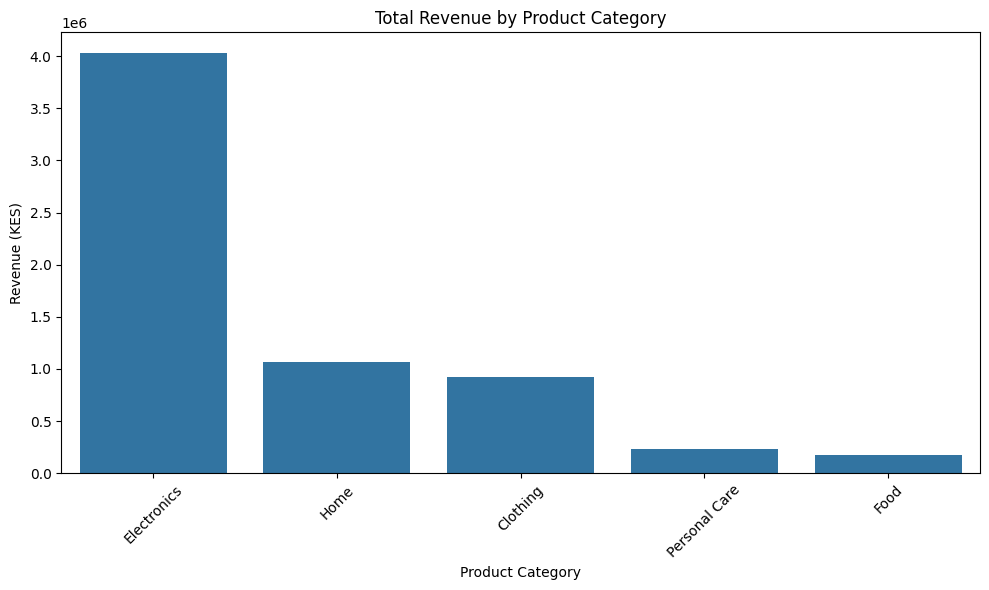

In [57]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_analysis,
    x="Product_Category",
    y="Total_Revenue_KES"
)

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [58]:
region_analysis = sales_data.groupby("Region").agg(
    Transaction_Count=("Transaction_ID", "nunique"),
    Total_Revenue_KES=("Revenue_KES", "sum"),
    Units_Sold=("Units_Sold", "sum")
).reset_index()

display(region_analysis)

,Region,Transaction_Count,Total_Revenue_KES,Units_Sold
0,Central,45,1423429.59,234
1,Coast,54,1061709.09,333
2,Nairobi,41,924519.16,194
3,Rift Valley,52,1282179.28,253
4,Western,63,1654311.32,259


In [59]:
channel_analysis = sales_data.groupby("Sales_Channel").agg(
    Transaction_Count=("Transaction_ID", "nunique"),
    Total_Revenue_KES=("Revenue_KES", "sum"),
    Units_Sold=("Units_Sold", "sum")
).reset_index()

display(channel_analysis)

,Sales_Channel,Transaction_Count,Total_Revenue_KES,Units_Sold
0,Online,100,2898053.61,454
1,Store,160,3526876.35,842


In [60]:
revenue_pivot = pd.pivot_table(
    sales_data,
    values="Revenue_KES",
    index="Product_Category",
    columns="Region",
    aggfunc="sum",
    fill_value=0
)

display(revenue_pivot)

Region,Central,Coast,Nairobi,Rift Valley,Western
Product_Category,,,,,
Clothing,119232.83,203416.77,157596.20,131407.45,308473.56
Electronics,1063001.49,568418.04,570396.39,784615.56,984440.40
Food,36952.77,47843.97,22064.68,25313.88,31572.35
Home,156697.96,202383.38,138384.40,250639.39,317673.56
Personal Care,47544.54,39646.93,36077.49,90203.00,12151.45


In [61]:
count_pivot = pd.pivot_table(
    sales_data,
    values="Transaction_ID",
    index="Product_Category",
    columns="Region",
    aggfunc="nunique",
    fill_value=0
)

display(count_pivot)

Region,Central,Coast,Nairobi,Rift Valley,Western
Product_Category,,,,,
Clothing,8,17,12,12,20
Electronics,9,7,6,4,13
Food,13,16,9,11,13
Home,6,8,6,12,13
Personal Care,9,6,8,13,4


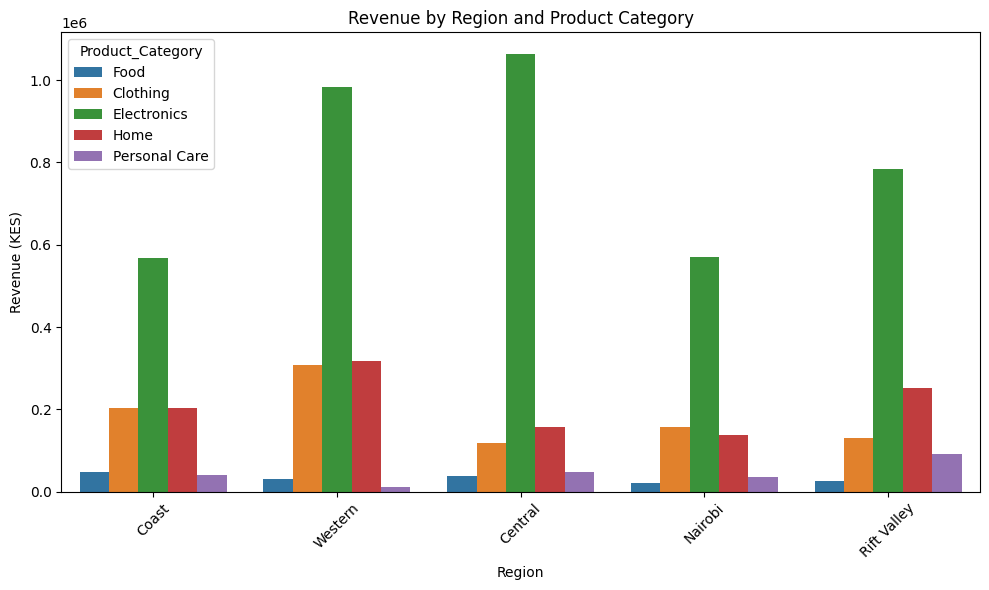

In [62]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=sales_data,
    x="Region",
    y="Revenue_KES",
    hue="Product_Category",
    estimator=sum,
    errorbar=None
)

plt.title("Revenue by Region and Product Category")
plt.xlabel("Region")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [63]:
sales_data["Date"] = pd.to_datetime(
    sales_data["Date"], errors="coerce"
)

# Remove records with invalid dates for time analysis only
time_data = sales_data.dropna(subset=["Date"]).copy()

time_data["Month"] = time_data["Date"].dt.to_period("M").astype(str)

time_data["Day"] = time_data["Date"].dt.date

In [64]:
monthly_sales = time_data.groupby("Month").agg(
    Total_Revenue_KES=("Revenue_KES", "sum"),
    Transaction_Count=("Transaction_ID", "nunique")
).reset_index()

display(monthly_sales)

highest_month = monthly_sales.loc[
    monthly_sales["Total_Revenue_KES"].idxmax()
]

lowest_month = monthly_sales.loc[
    monthly_sales["Total_Revenue_KES"].idxmin()
]

print("Highest revenue month:")
display(highest_month)

print("Lowest revenue month:")
display(lowest_month)

,Month,Total_Revenue_KES,Transaction_Count
0,2025-01,887737.28,44
1,2025-02,1441837.95,45
2,2025-03,852130.56,36
3,2025-04,1071471.48,43
4,2025-05,878043.38,35
5,2025-06,1293709.31,57


Highest revenue month:


,1
Month,2025-02
Total_Revenue_KES,1441837.95
Transaction_Count,45


Lowest revenue month:


,2
Month,2025-03
Total_Revenue_KES,852130.56
Transaction_Count,36


In [65]:
daily_sales = time_data.groupby("Day").agg(
    Total_Revenue_KES=("Revenue_KES", "sum"),
    Transaction_Count=("Transaction_ID", "nunique")
).reset_index()

display(daily_sales)

,Day,Total_Revenue_KES,Transaction_Count
0,2025-01-01,72378.36,2
1,2025-01-02,19985.44,3
2,2025-01-03,5701.51,2
3,2025-01-04,58689.69,3
4,2025-01-05,32686.80,6
...,...,...,...
134,2025-06-25,10660.79,1
135,2025-06-26,8212.93,1
136,2025-06-27,17829.50,2
137,2025-06-28,13820.39,1


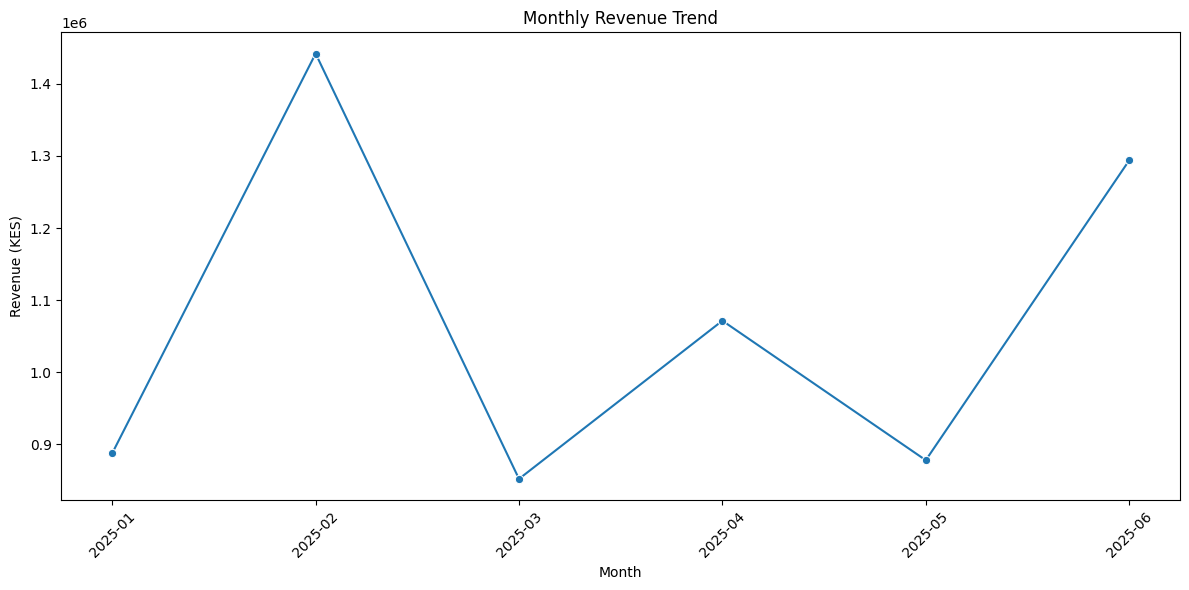

In [66]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Total_Revenue_KES",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [67]:
payment_analysis = sales_data.groupby("Payment_Method").agg(
    Transaction_Count=("Transaction_ID", "nunique"),
    Total_Revenue_KES=("Revenue_KES", "sum"),
    Average_Transaction_Value=("Revenue_KES", "mean")
).reset_index()

display(payment_analysis)

,Payment_Method,Transaction_Count,Total_Revenue_KES,Average_Transaction_Value
0,Bank Transfer,31,582504.91,18790.480968
1,Card,54,1568440.00,29045.185185
2,Cash,50,708325.59,14166.511800
3,Mobile Money,120,3363163.82,28026.365167


In [68]:
channel_comparison = sales_data.groupby("Sales_Channel").agg(
    Transaction_Count=("Transaction_ID", "nunique"),
    Total_Revenue_KES=("Revenue_KES", "sum"),
    Average_Transaction_Value=("Revenue_KES", "mean")
).reset_index()

display(channel_comparison)

,Sales_Channel,Transaction_Count,Total_Revenue_KES,Average_Transaction_Value
0,Online,100,2898053.61,28980.536100
1,Store,160,3526876.35,22042.977188


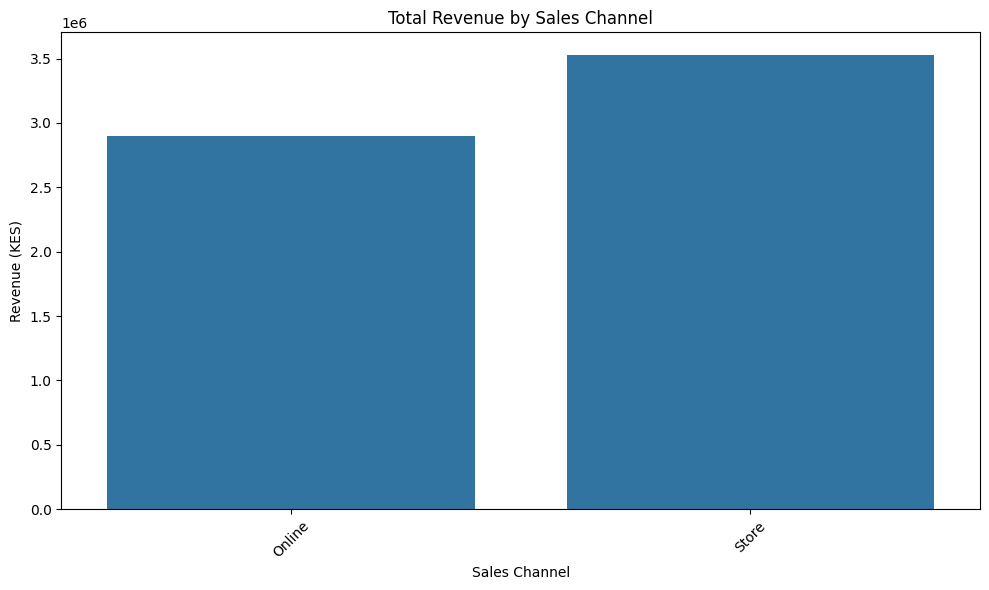

In [69]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=channel_comparison,
    x="Sales_Channel",
    y="Total_Revenue_KES"
)

plt.title("Total Revenue by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

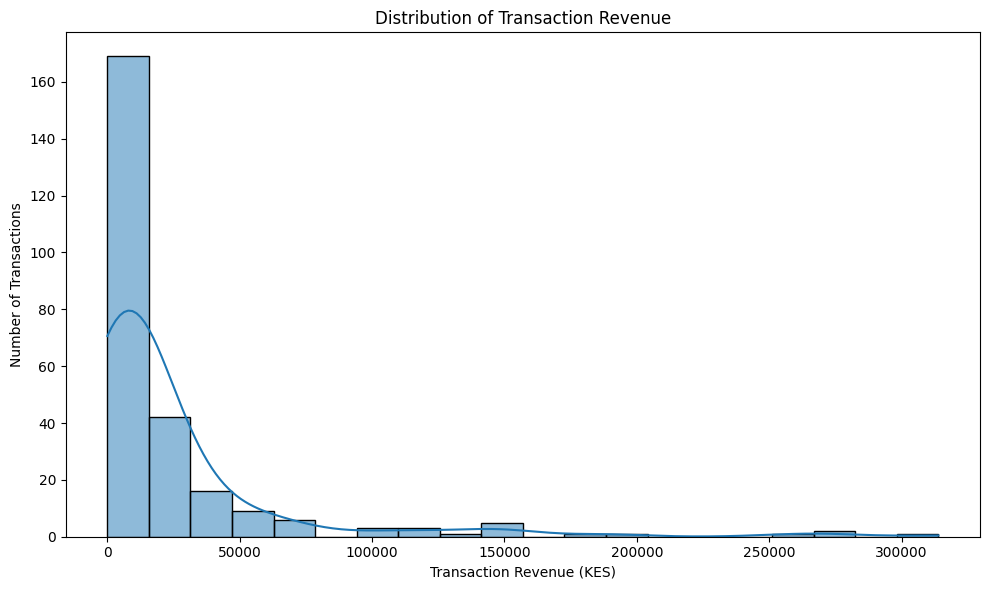

In [70]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=sales_data,
    x="Revenue_KES",
    bins=20,
    kde=True
)

plt.title("Distribution of Transaction Revenue")
plt.xlabel("Transaction Revenue (KES)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

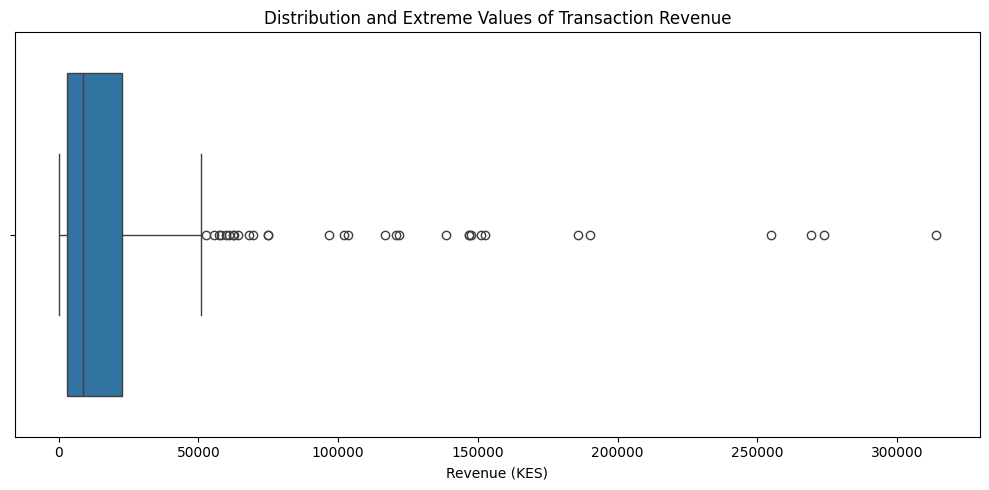

In [71]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=sales_data,
    x="Revenue_KES"
)

plt.title("Distribution and Extreme Values of Transaction Revenue")
plt.xlabel("Revenue (KES)")
plt.tight_layout()
plt.show()

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create a separate analysis copy
sales_data = retail_clean.copy()

# Convert numerical columns to numeric
numeric_columns = [
    "Units_Sold",
    "Unit_Price_KES",
    "Discount_Rate",
    "Revenue_KES"
]

for col in numeric_columns:
    sales_data[col] = pd.to_numeric(
        sales_data[col], errors="coerce"
    )

# Convert date to datetime
sales_data["Date"] = pd.to_datetime(
    sales_data["Date"], errors="coerce"
)

# Retain missing categories as Unknown for grouping
sales_data["Region"] = sales_data["Region"].fillna("Unknown")
sales_data["Payment_Method"] = sales_data["Payment_Method"].fillna("Unknown")

# Display dataset information
print("Dataset shape:", sales_data.shape)
display(sales_data.head())

Dataset shape: (260, 13)


,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES,Calculated_Revenue_KES,Revenue_Difference,Revenue_Status
0,TX0001,2025-03-20,Coast,Food,2,409.65,0.15,Mobile Money,Store,696.40,696.405,-0.005,Matches
1,TX0002,2025-06-29,Unknown,Food,8,1047.14,0.00,Mobile Money,Store,8377.12,8377.120,0.000,Matches
2,TX0003,2025-06-02,Coast,Clothing,1,1374.69,0.00,Card,Store,1374.69,1374.690,0.000,Matches
3,TX0004,2025-04-17,Coast,Clothing,3,3861.90,0.00,Cash,Store,11585.70,11585.700,0.000,Matches
4,TX0005,2025-01-05,Western,Food,1,701.62,0.15,Mobile Money,Online,596.38,596.377,0.003,Matches


In [73]:
# Select records with valid KPI information
kpi_data = sales_data.dropna(
    subset=["Revenue_KES", "Units_Sold", "Discount_Rate"]
)

kpi_data = kpi_data[
    (kpi_data["Units_Sold"] > 0) &
    (kpi_data["Revenue_KES"] >= 0) &
    (kpi_data["Discount_Rate"].between(0, 1))
]

# Calculate KPIs
total_revenue = kpi_data["Revenue_KES"].sum()
total_units = kpi_data["Units_Sold"].sum()
average_revenue = kpi_data["Revenue_KES"].mean()
median_revenue = kpi_data["Revenue_KES"].median()
transaction_count = kpi_data["Transaction_ID"].nunique()
average_discount = kpi_data["Discount_Rate"].mean()

# Display results
print("RETAIL SALES PERFORMANCE")
print("=========================")
print(f"Total Revenue: KES {total_revenue:,.2f}")
print(f"Total Units Sold: {total_units:,.0f}")
print(f"Average Transaction Revenue: KES {average_revenue:,.2f}")
print(f"Median Transaction Revenue: KES {median_revenue:,.2f}")
print(f"Transaction Count: {transaction_count}")
print(f"Average Discount: {average_discount:.2%}")

RETAIL SALES PERFORMANCE
Total Revenue: KES 6,424,929.96
Total Units Sold: 1,296
Average Transaction Revenue: KES 24,711.27
Median Transaction Revenue: KES 8,920.24
Transaction Count: 260
Average Discount: 7.48%


In [74]:
category_analysis = sales_data.groupby(
    "Product_Category"
).agg(
    Transaction_Count=("Transaction_ID", "nunique"),
    Total_Revenue_KES=("Revenue_KES", "sum"),
    Units_Sold=("Units_Sold", "sum"),
    Average_Selling_Price=("Unit_Price_KES", "mean"),
    Average_Discount=("Discount_Rate", "mean")
).reset_index()

# Rank by revenue and units sold
category_analysis["Revenue_Rank"] = (
    category_analysis["Total_Revenue_KES"]
    .rank(method="min", ascending=False)
)

category_analysis["Units_Rank"] = (
    category_analysis["Units_Sold"]
    .rank(method="min", ascending=False)
)

category_analysis = category_analysis.sort_values(
    "Total_Revenue_KES", ascending=False
)

display(category_analysis)

,Product_Category,Transaction_Count,Total_Revenue_KES,Units_Sold,Average_Selling_Price,Average_Discount,Revenue_Rank,Units_Rank
1,Electronics,40,4028427.69,195,29762.506500,0.077500,1.0,5.0
3,Home,46,1069554.46,294,6446.092889,0.072826,2.0,3.0
0,Clothing,69,920126.81,302,3435.850000,0.085507,3.0,1.0
4,Personal Care,42,234696.23,207,1240.026429,0.067857,4.0,4.0
2,Food,63,172124.77,298,606.756833,0.067460,5.0,2.0


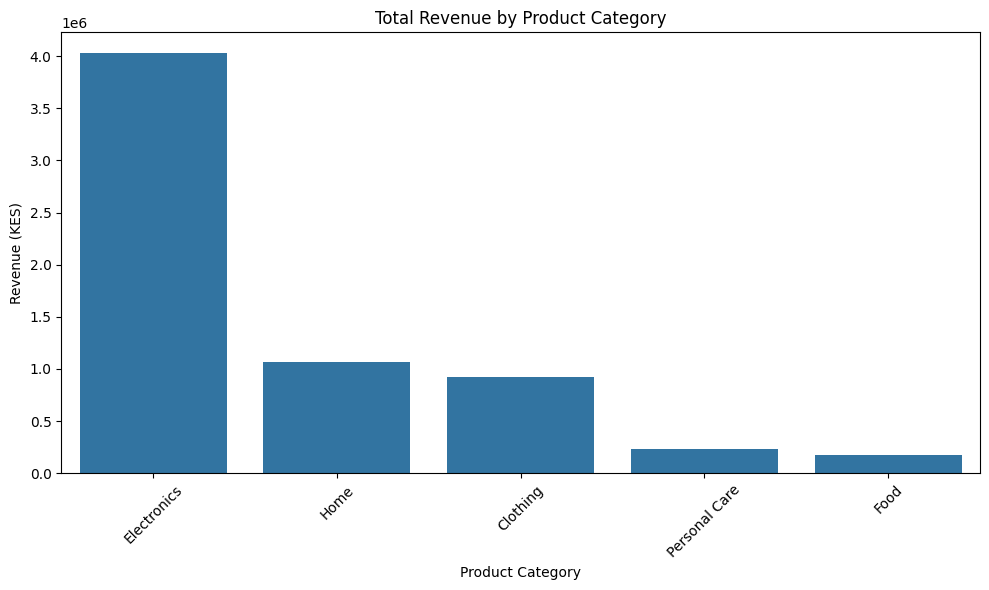

In [75]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_analysis,
    x="Product_Category",
    y="Total_Revenue_KES"
)

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [76]:
region_analysis = sales_data.groupby("Region").agg(
    Transaction_Count=("Transaction_ID", "nunique"),
    Total_Revenue_KES=("Revenue_KES", "sum"),
    Units_Sold=("Units_Sold", "sum")
).reset_index()

display(region_analysis)

,Region,Transaction_Count,Total_Revenue_KES,Units_Sold
0,Central,45,1423429.59,234
1,Coast,54,1061709.09,333
2,Nairobi,41,924519.16,194
3,Rift Valley,52,1282179.28,253
4,Unknown,5,78781.52,23
5,Western,63,1654311.32,259


In [77]:
channel_analysis = sales_data.groupby("Sales_Channel").agg(
    Transaction_Count=("Transaction_ID", "nunique"),
    Total_Revenue_KES=("Revenue_KES", "sum"),
    Units_Sold=("Units_Sold", "sum")
).reset_index()

display(channel_analysis)

,Sales_Channel,Transaction_Count,Total_Revenue_KES,Units_Sold
0,Online,100,2898053.61,454
1,Store,160,3526876.35,842


In [78]:
revenue_pivot = pd.pivot_table(
    sales_data,
    values="Revenue_KES",
    index="Product_Category",
    columns="Region",
    aggfunc="sum",
    fill_value=0
)

display(revenue_pivot)

Region,Central,Coast,Nairobi,Rift Valley,Unknown,Western
Product_Category,,,,,,
Clothing,119232.83,203416.77,157596.20,131407.45,0.00,308473.56
Electronics,1063001.49,568418.04,570396.39,784615.56,57555.81,984440.40
Food,36952.77,47843.97,22064.68,25313.88,8377.12,31572.35
Home,156697.96,202383.38,138384.40,250639.39,3775.77,317673.56
Personal Care,47544.54,39646.93,36077.49,90203.00,9072.82,12151.45


In [79]:
count_pivot = pd.pivot_table(
    sales_data,
    values="Transaction_ID",
    index="Product_Category",
    columns="Region",
    aggfunc="nunique",
    fill_value=0
)

display(count_pivot)

Region,Central,Coast,Nairobi,Rift Valley,Unknown,Western
Product_Category,,,,,,
Clothing,8,17,12,12,0,20
Electronics,9,7,6,4,1,13
Food,13,16,9,11,1,13
Home,6,8,6,12,1,13
Personal Care,9,6,8,13,2,4


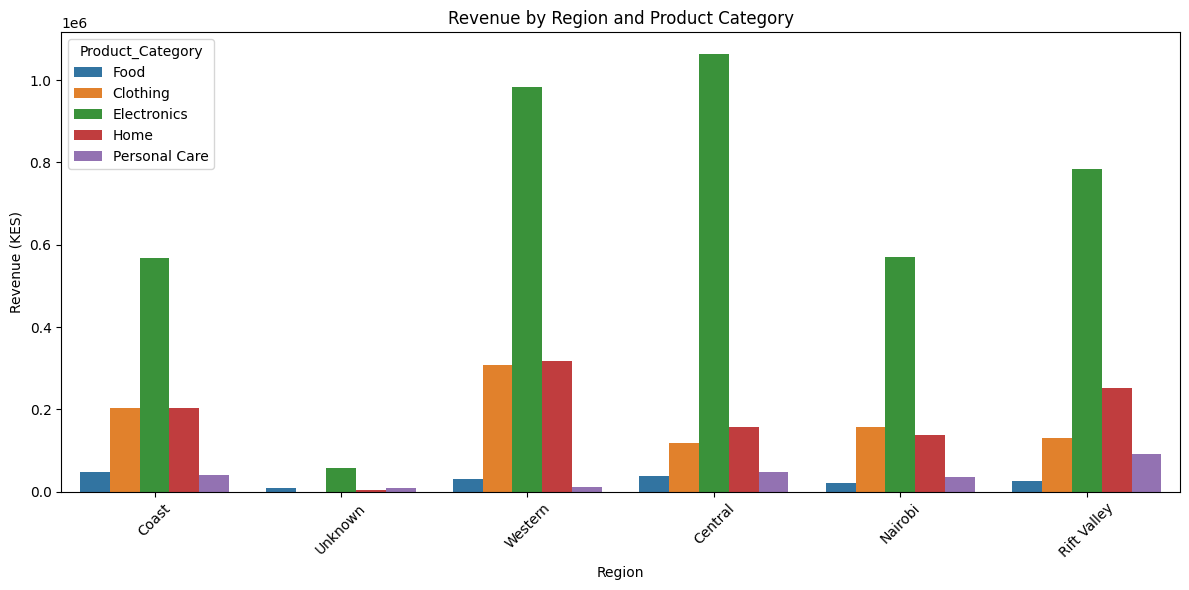

In [80]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=sales_data,
    x="Region",
    y="Revenue_KES",
    hue="Product_Category",
    estimator="sum",
    errorbar=None
)

plt.title("Revenue by Region and Product Category")
plt.xlabel("Region")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [81]:
time_data = sales_data.dropna(subset=["Date"]).copy()

time_data["Month"] = time_data["Date"].dt.to_period("M").astype(str)

time_data["Day"] = time_data["Date"].dt.date

In [82]:
monthly_sales = time_data.groupby("Month").agg(
    Total_Revenue_KES=("Revenue_KES", "sum"),
    Transaction_Count=("Transaction_ID", "nunique")
).reset_index()

display(monthly_sales)

# Highest revenue month
highest_month = monthly_sales.loc[
    monthly_sales["Total_Revenue_KES"].idxmax()
]

# Lowest revenue month
lowest_month = monthly_sales.loc[
    monthly_sales["Total_Revenue_KES"].idxmin()
]

print("Highest revenue month:")
display(highest_month)

print("Lowest revenue month:")
display(lowest_month)

,Month,Total_Revenue_KES,Transaction_Count
0,2025-01,887737.28,44
1,2025-02,1441837.95,45
2,2025-03,852130.56,36
3,2025-04,1071471.48,43
4,2025-05,878043.38,35
5,2025-06,1293709.31,57


Highest revenue month:


,1
Month,2025-02
Total_Revenue_KES,1441837.95
Transaction_Count,45


Lowest revenue month:


,2
Month,2025-03
Total_Revenue_KES,852130.56
Transaction_Count,36


In [83]:
daily_sales = time_data.groupby("Day").agg(
    Total_Revenue_KES=("Revenue_KES", "sum"),
    Transaction_Count=("Transaction_ID", "nunique")
).reset_index()

display(daily_sales)

,Day,Total_Revenue_KES,Transaction_Count
0,2025-01-01,72378.36,2
1,2025-01-02,19985.44,3
2,2025-01-03,5701.51,2
3,2025-01-04,58689.69,3
4,2025-01-05,32686.80,6
...,...,...,...
134,2025-06-25,10660.79,1
135,2025-06-26,8212.93,1
136,2025-06-27,17829.50,2
137,2025-06-28,13820.39,1


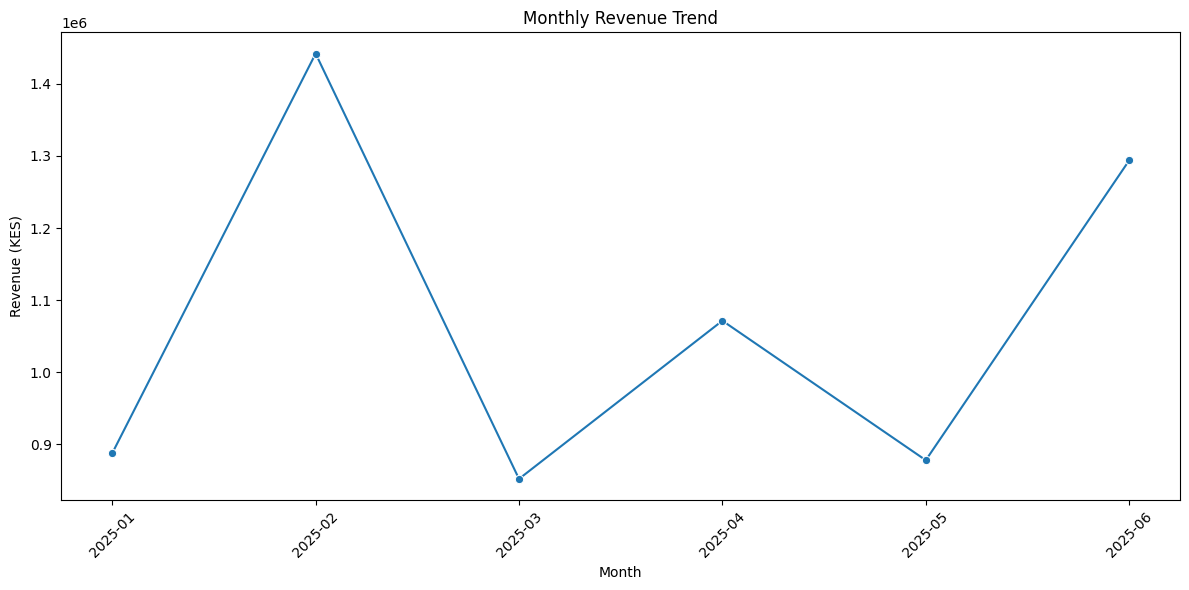

In [84]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Total_Revenue_KES",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [85]:
payment_analysis = sales_data.groupby("Payment_Method").agg(
    Transaction_Count=("Transaction_ID", "nunique"),
    Total_Revenue_KES=("Revenue_KES", "sum"),
    Average_Transaction_Value=("Revenue_KES", "mean")
).reset_index()

display(payment_analysis)

,Payment_Method,Transaction_Count,Total_Revenue_KES,Average_Transaction_Value
0,Bank Transfer,31,582504.91,18790.480968
1,Card,54,1568440.00,29045.185185
2,Cash,50,708325.59,14166.511800
3,Mobile Money,120,3363163.82,28026.365167
4,Unknown,5,202495.64,40499.128000


In [86]:
channel_comparison = sales_data.groupby("Sales_Channel").agg(
    Transaction_Count=("Transaction_ID", "nunique"),
    Total_Revenue_KES=("Revenue_KES", "sum"),
    Average_Transaction_Value=("Revenue_KES", "mean")
).reset_index()

display(channel_comparison)

,Sales_Channel,Transaction_Count,Total_Revenue_KES,Average_Transaction_Value
0,Online,100,2898053.61,28980.536100
1,Store,160,3526876.35,22042.977188


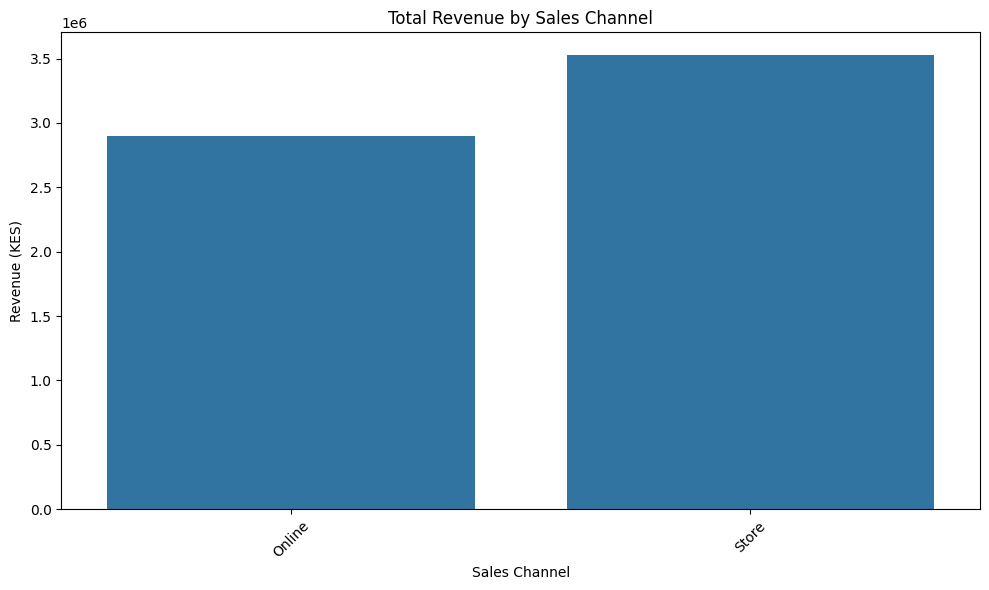

In [87]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=channel_comparison,
    x="Sales_Channel",
    y="Total_Revenue_KES"
)

plt.title("Total Revenue by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

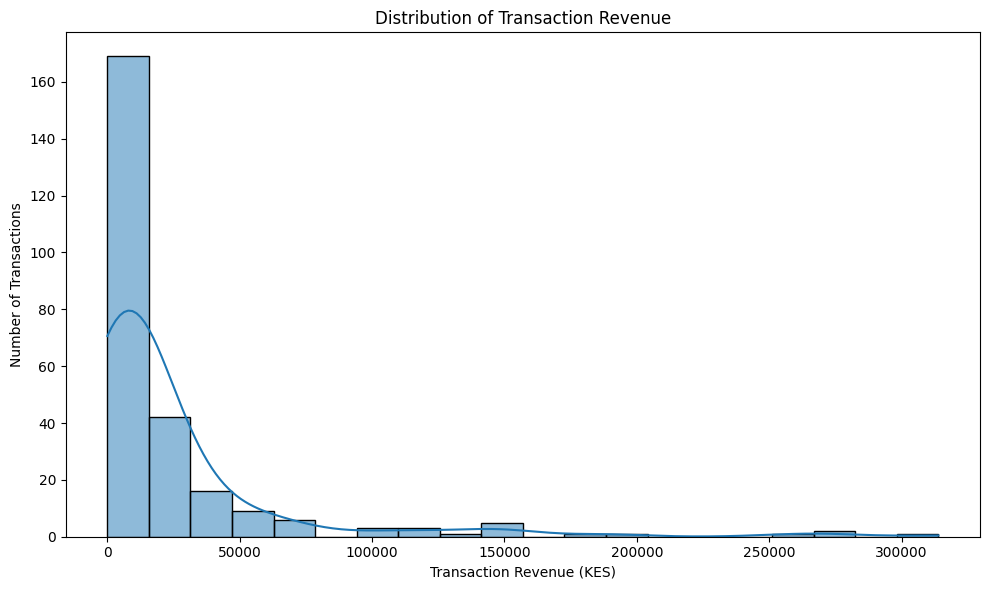

In [88]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=sales_data,
    x="Revenue_KES",
    bins=20,
    kde=True
)

plt.title("Distribution of Transaction Revenue")
plt.xlabel("Transaction Revenue (KES)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

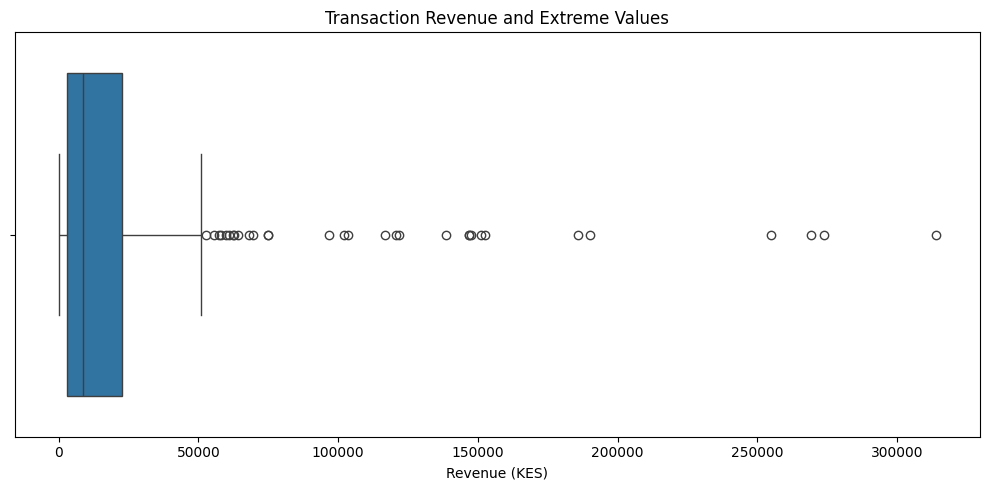

In [89]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=sales_data,
    x="Revenue_KES"
)

plt.title("Transaction Revenue and Extreme Values")
plt.xlabel("Revenue (KES)")
plt.tight_layout()
plt.show()

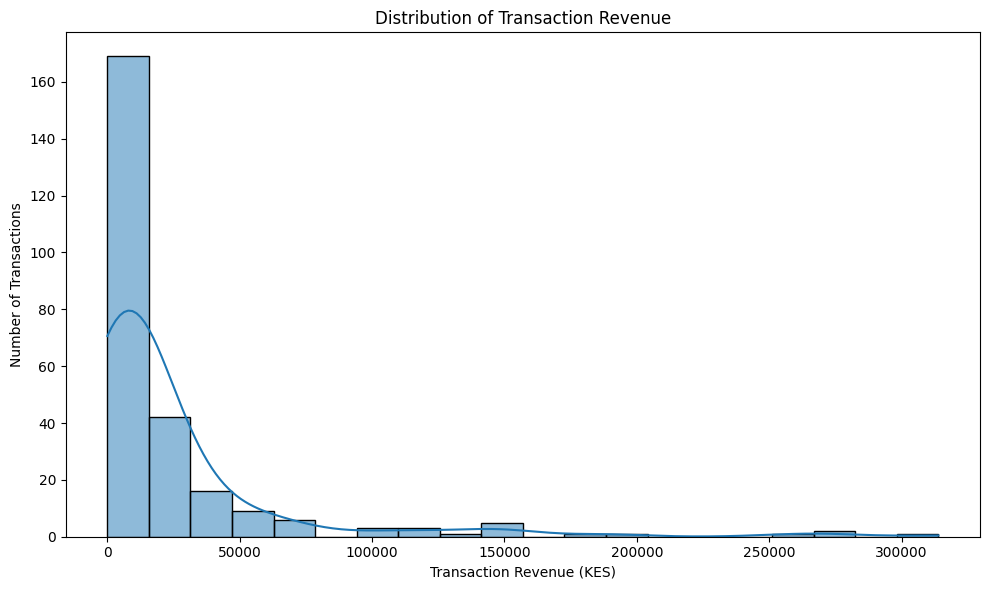

In [90]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=sales_data,
    x="Revenue_KES",
    bins=20,
    kde=True
)

plt.title("Distribution of Transaction Revenue")
plt.xlabel("Transaction Revenue (KES)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

In [91]:
with pd.ExcelWriter("Part_B_Retail_Sales_Results.xlsx") as writer:

    kpi_table = pd.DataFrame({
        "KPI": [
            "Total Revenue (KES)",
            "Total Units Sold",
            "Average Transaction Revenue (KES)",
            "Median Transaction Revenue (KES)",
            "Transaction Count",
            "Average Discount"
        ],
        "Value": [
            total_revenue,
            total_units,
            average_revenue,
            median_revenue,
            transaction_count,
            average_discount
        ]
    })

    kpi_table.to_excel(writer, sheet_name="KPIs", index=False)
    category_analysis.to_excel(writer, sheet_name="Category Analysis", index=False)
    region_analysis.to_excel(writer, sheet_name="Region Analysis", index=False)
    channel_analysis.to_excel(writer, sheet_name="Channel Analysis", index=False)
    monthly_sales.to_excel(writer, sheet_name="Monthly Sales", index=False)
    daily_sales.to_excel(writer, sheet_name="Daily Sales", index=False)
    payment_analysis.to_excel(writer, sheet_name="Payment Analysis", index=False)
    revenue_pivot.to_excel(writer, sheet_name="Revenue Pivot")
    count_pivot.to_excel(writer, sheet_name="Transaction Pivot")

print("Part B results saved successfully!")

Part B results saved successfully!


In [92]:
# Work on a copy of the Part B dataset
model_data = sales_data.copy()

# Create date-based features
model_data["Month"] = model_data["Date"].dt.month
model_data["Day_of_Week"] = model_data["Date"].dt.dayofweek
model_data["Is_Weekend"] = (
    model_data["Day_of_Week"] >= 5
).astype(int)

# Calculate total discount amount in KES
model_data["Discount_Amount_KES"] = (
    model_data["Units_Sold"] *
    model_data["Unit_Price_KES"] *
    model_data["Discount_Rate"]
)

# Display the new features
display(model_data[
    [
        "Date",
        "Month",
        "Day_of_Week",
        "Is_Weekend",
        "Discount_Amount_KES"
    ]
].head())

,Date,Month,Day_of_Week,Is_Weekend,Discount_Amount_KES
0,2025-03-20,3,3,0,122.895
1,2025-06-29,6,6,1,0.000
2,2025-06-02,6,0,0,0.000
3,2025-04-17,4,3,0,0.000
4,2025-01-05,1,6,1,105.243


In [93]:
# Target variable: transaction revenue
target = "Revenue_KES"

# Features used to predict revenue
features = [
    "Units_Sold",
    "Unit_Price_KES",
    "Discount_Rate",
    "Product_Category",
    "Region",
    "Payment_Method",
    "Sales_Channel",
    "Month",
    "Day_of_Week",
    "Is_Weekend"
]

# Keep records with a valid target
model_data = model_data.dropna(subset=[target])

# Remove invalid target values
model_data = model_data[model_data[target] >= 0]

X = model_data[features]
y = model_data[target]

print("Number of observations:", len(model_data))
print("Number of predictors:", len(features))

display(X.head())

Number of observations: 260
Number of predictors: 10


,Units_Sold,Unit_Price_KES,Discount_Rate,Product_Category,Region,Payment_Method,Sales_Channel,Month,Day_of_Week,Is_Weekend
0,2,409.65,0.15,Food,Coast,Mobile Money,Store,3,3,0
1,8,1047.14,0.00,Food,Unknown,Mobile Money,Store,6,6,1
2,1,1374.69,0.00,Clothing,Coast,Card,Store,6,0,0
3,3,3861.90,0.00,Clothing,Coast,Cash,Store,4,3,0
4,1,701.62,0.15,Food,Western,Mobile Money,Online,1,6,1


In [96]:
numeric_features = [
    "Units_Sold",
    "Unit_Price_KES",
    "Discount_Rate",
    "Month",
    "Day_of_Week",
    "Is_Weekend"
]

categorical_features = [
    "Product_Category",
    "Region",
    "Payment_Method",
    "Sales_Channel"
]

# Process numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Process categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.
